In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/superstore_sales.csv', encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [7]:
print("Missing Values:\n", df.isnull().sum())
df.drop_duplicates(inplace=True)
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

print("\nData cleaning complete! new Year-Month column ")
df[['Order Date', 'Year-Month']].head()

Missing Values:
 Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year-Month       0
dtype: int64

Data cleaning complete! new Year-Month column 


,Order Date,Year-Month
0,2017-11-08,2017-11
1,2017-11-08,2017-11
2,2017-06-12,2017-06
3,2016-10-11,2016-10
4,2016-10-11,2016-10


In [6]:
df.dropna(subset=['Order Date', 'Sales'], inplace=True)
df['Postal Code'] = df['Postal Code'].fillna(0)

print("After cleaning remaining missing values:\n", df.isnull().sum().sum())
print("Total clean rows:", len(df))

After cleaning remaining missing values:
 0
Total clean rows: 9994


In [8]:
cat_summary = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()
print("--- Category Summary ---")
print(cat_summary)
reg_summary = df.groupby('Region')[['Sales', 'Profit']].sum().reset_index()
print("\n--- Region Summary ---")
print(reg_summary)
seg_summary = df.groupby('Segment')[['Sales', 'Profit']].sum().reset_index()
print("\n--- Segment Summary ---")
print(seg_summary)

--- Category Summary ---
          Category        Sales       Profit
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008
2       Technology  836154.0330  145454.9481

--- Region Summary ---
    Region        Sales       Profit
0  Central  501239.8908   39706.3625
1     East  678781.2400   91522.7800
2    South  391721.9050   46749.4303
3     West  725457.8245  108418.4489

--- Segment Summary ---
       Segment         Sales       Profit
0     Consumer  1.161401e+06  134119.2092
1    Corporate  7.061464e+05   91979.1340
2  Home Office  4.296531e+05   60298.6785


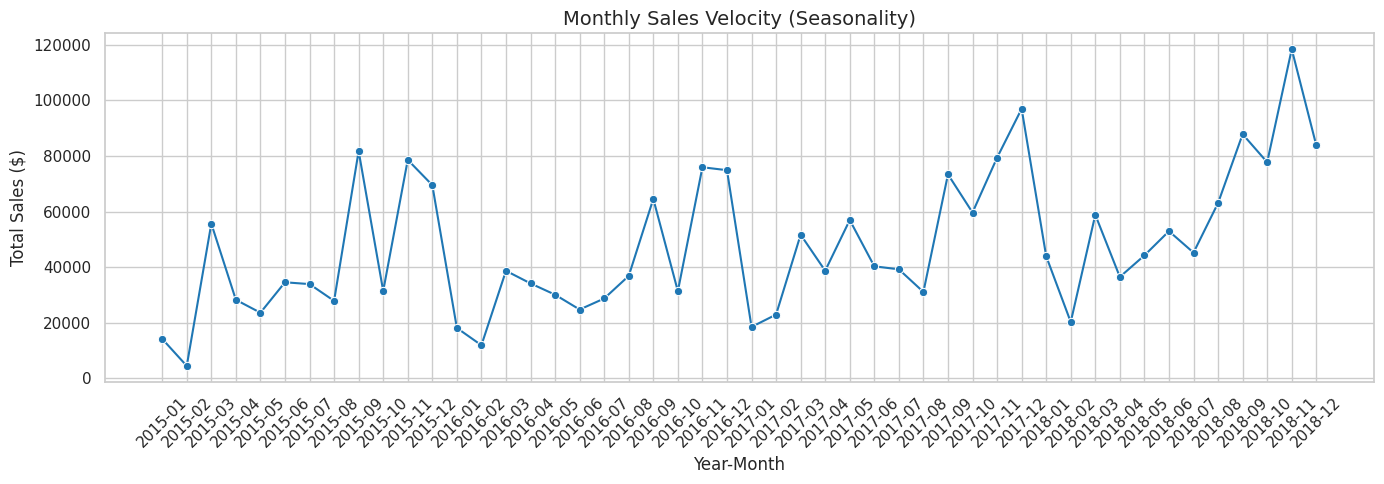

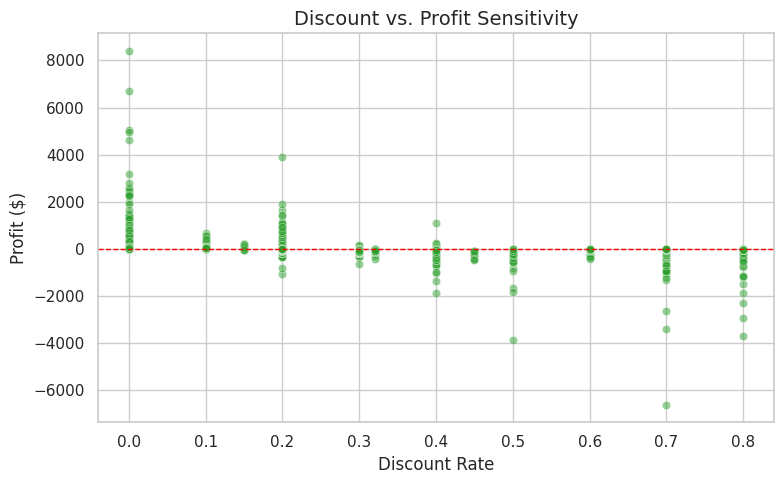

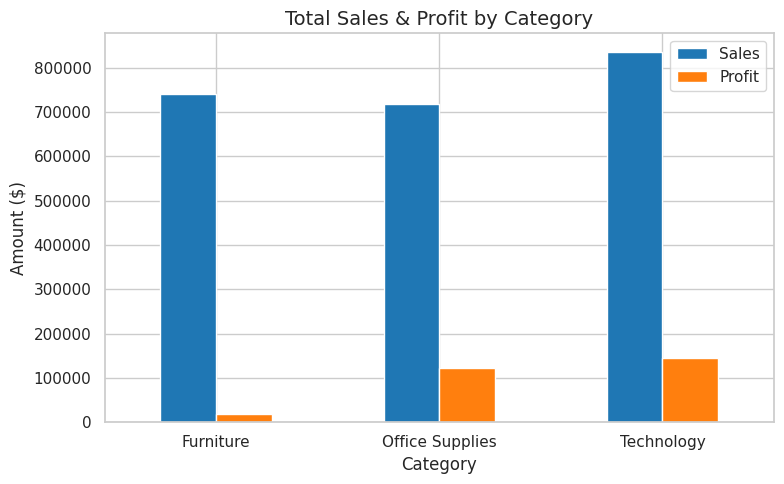

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


monthly_sales = df.groupby('Year-Month')['Sales'].sum().reset_index()

plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly_sales, x='Year-Month', y='Sales', marker='o', color='#1f77b4')
plt.xticks(rotation=45)
plt.title('Monthly Sales Velocity (Seasonality)', fontsize=14)
plt.xlabel('Year-Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.5, color='#2ca02c')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title('Discount vs. Profit Sensitivity', fontsize=14)
plt.xlabel('Discount Rate')
plt.ylabel('Profit ($)')
plt.tight_layout()
plt.show()


cat_summary.plot(x='Category', y=['Sales', 'Profit'], kind='bar', figsize=(8, 5), color=['#1f77b4', '#ff7f0e'])
plt.title('Total Sales & Profit by Category', fontsize=14)
plt.xticks(rotation=0)
plt.ylabel('Amount ($)')
plt.tight_layout()
plt.show()